# API 7: Pruning

We usually use pruning to make neural networks sparser hence more efficient and more interpretable. KANs provide two ways of pruning: automatic pruning, and manual pruning.

## Pruning nodes

cuda


train RMSE 0.051587598645370374 test RMSE 0.052629512265236454


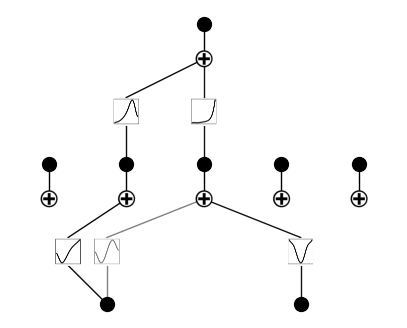

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import prune, prune_edge, prune_node
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)

# create dataset f(x,y) = exp(sin(pi*x)+y^2)
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

# train the model
history = fit(model, train, test, steps=20, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

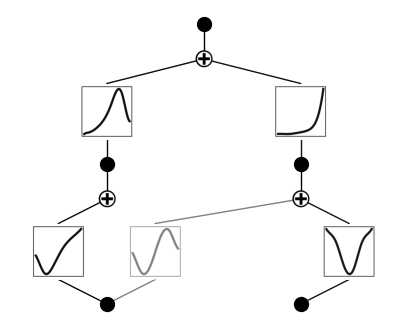

In [2]:
mode = 'auto'

if mode == 'auto':
    # automatic
    model = prune_node(model, train['x'], threshold=1e-2) # by default the threshold is 1e-2
    plot(model, train['x'])
elif mode == 'manual':
    # manual
    model = prune_node(model, train['x'], keep=[[0]])

## Pruning Edges

train RMSE 0.06311960355429139 test RMSE 0.06061293858684924


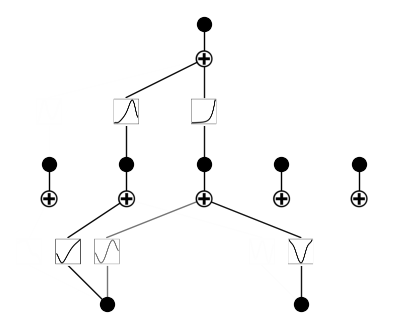

In [3]:
from xkan import KANNetwork, create_dataset, fit
# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)

# create dataset f(x,y) = exp(sin(pi*x)+y^2)
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

# train the model
history = fit(model, train, test, steps=6, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

In [4]:
model = prune_edge(model, train['x'])

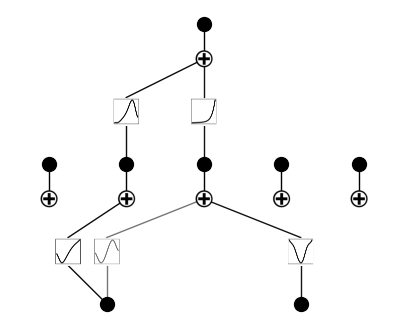

In [5]:
plot(model, train['x']);

## Prune nodes and edges together

`prune(model, x)` prunes nodes and edges in one call.

train RMSE 0.051587598645370374 test RMSE 0.052629512265236454


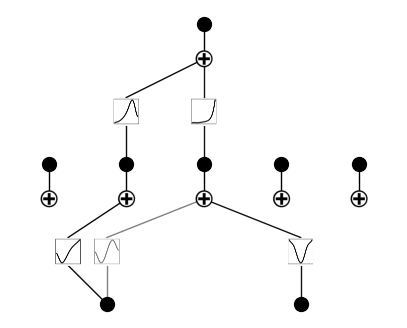

In [6]:
from xkan import KANNetwork, create_dataset, fit
# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)

# create dataset f(x,y) = exp(sin(pi*x)+y^2)
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

# train the model
history = fit(model, train, test, steps=20, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

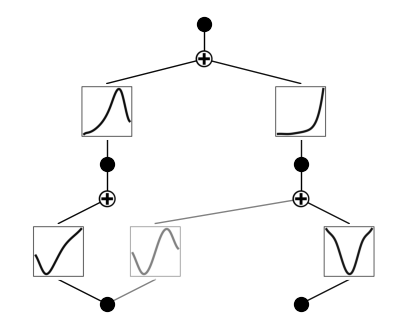

In [7]:
model = prune(model, train['x'])
plot(model, train['x']);